# Stage 04: Baseline Model Training and Evaluation


This notebook represents the first Machine Learning model training and evaluation stage for the Email Spam and Phishing Detection System. Our goal is: **TRAIN → EVALUATE → COMPARE → UNDERSTAND → SELECT**.


## Machine Learning Concepts (Part D)
Throughout this notebook, we will use several key concepts:
1. **What is model training?** The process where a machine learning algorithm learns patterns from historical data (features and labels) to make predictions on new data.
2. **What is a baseline model?** A simple, initial model used as a reference point to evaluate whether more complex models actually provide significant improvements.
3. **Why compare multiple algorithms?** Different algorithms make different assumptions about the data. Comparing them helps identify which mathematical approach works best for our specific problem.
4. **Why do we keep test data unseen?** To get an honest evaluation of how the model will perform in the real world. If a model learns from test data, it might just memorize answers (overfitting).
13. **Overfitting:** When a model learns the training data too perfectly, including its noise and outliers, causing it to perform poorly on new, unseen data.
14. **Underfitting:** When a model is too simple to capture the underlying patterns in the data, performing poorly on both training and test sets.



## DATA LEAKAGE VERIFICATION
Before training, we must verify our pipeline prevents data leakage:
- [x] TF-IDF was fitted only on training data.
- [x] Test data was not used during training.
- [x] Scaler is fitted only on training data.
- [x] No target column is present in X.
- [x] No test-set feature selection.
- [x] No test-set hyperparameter tuning.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

# Classifiers
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Create output directory
os.makedirs('../outputs/models', exist_ok=True)
sns.set_theme(style='whitegrid')
import warnings
warnings.filterwarnings('ignore')



============================================================
PART A — EMAIL SPAM/HAM CLASSIFICATION
============================================================


### Dataset: Enron Spam Dataset
Total: 33,716 emails
Class distribution: Spam = 17,171, Ham = 16,545

**Target Mapping:**
- Spam = 1 (Positive class)
- Ham = 0 (Negative class)

We will use the train/test split and TF-IDF pipeline designed during preprocessing.
*Note: We do not use SMOTE because the dataset is approximately balanced.*


In [2]:
# Re-creating the preprocessed email data for modeling
df_email = pd.read_csv('../data/raw/enron_spam_data.csv')
df_email = df_email.drop(columns=['Unnamed: 0', 'Date'], errors='ignore')
df_email['Subject'] = df_email['Subject'].fillna('')
df_email['Message'] = df_email['Message'].fillna('')
df_email['email_text'] = df_email['Subject'] + ' ' + df_email['Message']

import re
def preprocess_text(text):
    if not isinstance(text, str): return ""
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http[s]?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_email['email_text_clean'] = df_email['email_text'].apply(preprocess_text)
df_email['y_email'] = df_email['Spam/Ham'].map({'ham': 0, 'spam': 1})

# Train/Test Split
X_email = df_email['email_text_clean']
y_email = df_email['y_email']

X_email_train, X_email_test, y_email_train, y_email_test = train_test_split(
    X_email, y_email, test_size=0.20, random_state=42, stratify=y_email
)

# TF-IDF Vectorization
tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_df=0.95, sublinear_tf=True)
X_email_train_tfidf = tfidf.fit_transform(X_email_train)
X_email_test_tfidf = tfidf.transform(X_email_test)

print(f"Training matrix shape: {X_email_train_tfidf.shape}")
print(f"Testing matrix shape: {X_email_test_tfidf.shape}")



Training matrix shape: (26972, 107362)
Testing matrix shape: (6744, 107362)


### Algorithms Used
15. **Naive Bayes (MultinomialNB):** A probabilistic classifier based on Bayes' theorem, assuming features (words) are independent. Often a strong baseline for text classification.
16. **Logistic Regression:** A linear model that estimates the probability of a binary outcome. It works very well on high-dimensional sparse data like TF-IDF.
17. **Linear SVM (LinearSVC):** Finds the best hyperplane (line) that separates the two classes with the maximum margin. Highly effective for text classification.



### Evaluation Metrics Concepts
5. **Accuracy:** The percentage of total predictions (both spam and ham) that were correct.
6. **Precision:** Out of all emails predicted as Spam, how many were actually Spam? (Minimizes false positives).
7. **Recall:** Out of all actual Spam emails, how many did the model detect? (Minimizes false negatives).
8. **F1-score:** The harmonic mean of precision and recall. A balanced metric when you care about both.
9. **ROC-AUC:** Area Under the Receiver Operating Characteristic Curve. Measures the model's ability to distinguish between classes at various threshold settings.
10. **Confusion Matrix:** A table showing True Positives, True Negatives, False Positives, and False Negatives.
11. **False Positive:** Predicting Spam when it is actually Ham (e.g., blocking a legitimate email).
12. **False Negative:** Predicting Ham when it is actually Spam (e.g., letting a malicious email into the inbox).

**Security Context Note:** A False Negative in spam/phishing means an actual malicious email bypassed the filter and reached the user. This is highly undesirable in security systems. However, we cannot simply maximize recall to 100%, because doing so would classify everything as spam (high False Positives), breaking the email system. This is the **Precision-Recall Trade-off**.



In [3]:
# Train and Evaluate Email Models
email_models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(random_state=42)
}

email_results = []
email_predictions = {}

for name, model in email_models.items():
    print(f"Training {name}...")
    model.fit(X_email_train_tfidf, y_email_train)
    y_pred = model.predict(X_email_test_tfidf)
    email_predictions[name] = y_pred
    
    # Calculate metrics
    acc = accuracy_score(y_email_test, y_pred)
    prec = precision_score(y_email_test, y_pred)
    rec = recall_score(y_email_test, y_pred)
    f1 = f1_score(y_email_test, y_pred)
    
    # ROC-AUC requires probabilities or decision function
    if hasattr(model, "predict_proba"):
        roc = roc_auc_score(y_email_test, model.predict_proba(X_email_test_tfidf)[:, 1])
    elif hasattr(model, "decision_function"):
        roc = roc_auc_score(y_email_test, model.decision_function(X_email_test_tfidf))
    else:
        roc = np.nan
        
    email_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'ROC-AUC': roc
    })

df_email_results = pd.DataFrame(email_results)
print("\nEMAIL MODEL COMPARISON:")
display(df_email_results)



Training Multinomial Naive Bayes...
Training Logistic Regression...
Training Linear SVM...

EMAIL MODEL COMPARISON:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Multinomial Naive Bayes,0.989176,0.979190,1.0,0.989486,0.999698
1,Logistic Regression,0.999407,0.998837,1.0,0.999418,0.999815
2,Linear SVM,0.999407,0.998837,1.0,0.999418,0.999620


### Email Confusion Matrices & F1 Comparison


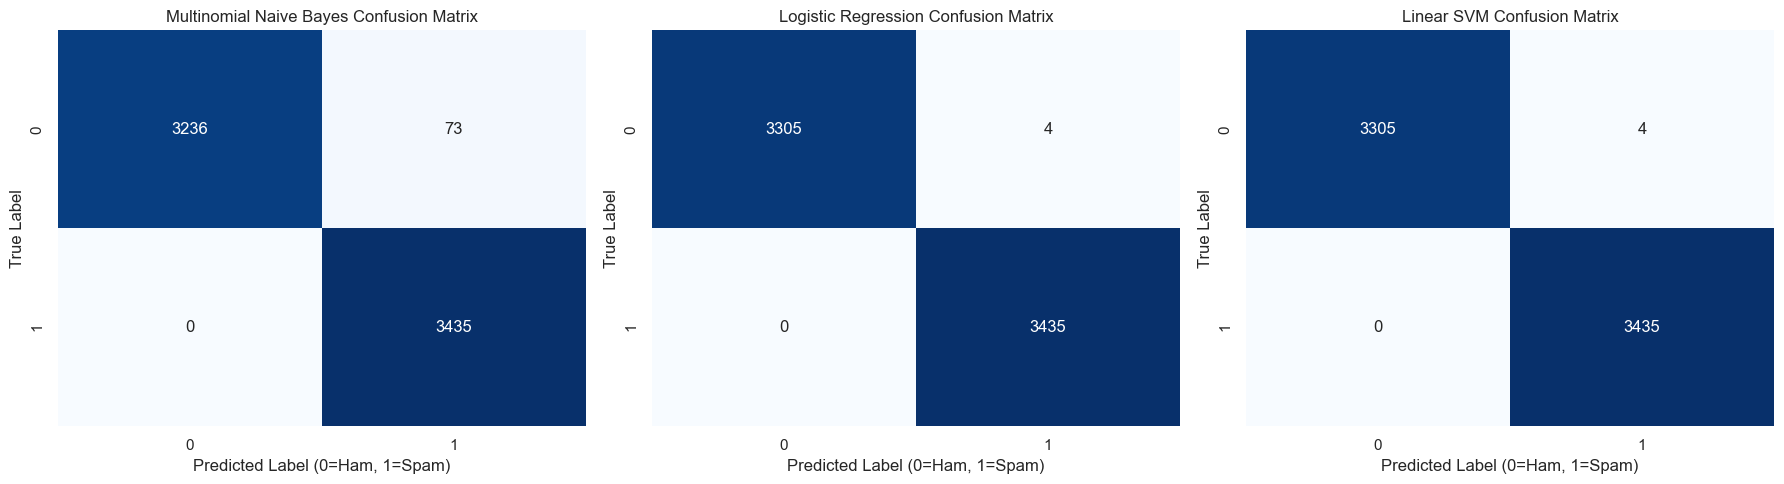

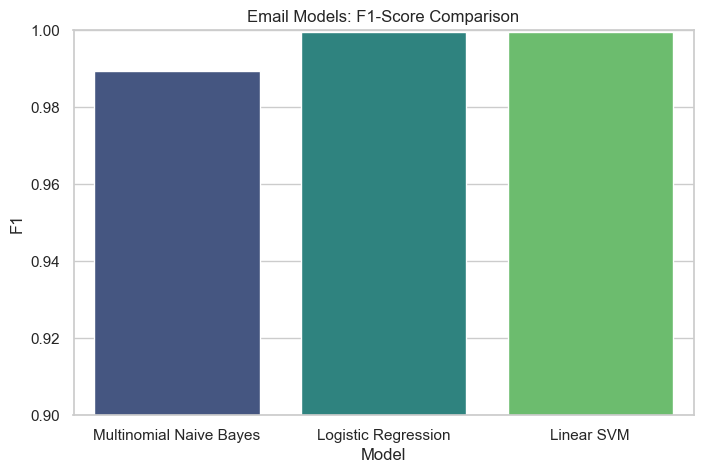

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, name in enumerate(email_models.keys()):
    cm = confusion_matrix(y_email_test, email_predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name} Confusion Matrix')
    axes[idx].set_xlabel('Predicted Label (0=Ham, 1=Spam)')
    axes[idx].set_ylabel('True Label')
plt.tight_layout()
plt.savefig('../outputs/models/email_confusion_matrices.png')
plt.show()

# F1 Score Comparison Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=df_email_results, x='Model', y='F1', palette='viridis')
plt.title('Email Models: F1-Score Comparison')
plt.ylim(0.9, 1.0)
plt.savefig('../outputs/models/email_f1_comparison.png')
plt.show()



### Email Feature Interpretation
These features represent the model's learned associations and are not absolute rules. A single word doesn't definitively make an email spam, but its presence strongly shifts the model's probability.
20. **Feature importance:** Indicates how strongly a feature contributed to the model's decisions.



In [5]:
def get_top_features_linear(model, vectorizer, n=20):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]
    
    top_spam_indices = coefs.argsort()[-n:][::-1]
    top_ham_indices = coefs.argsort()[:n]
    
    print("Top 20 SPAM Features (Positive Coefficients):")
    print(", ".join([feature_names[i] for i in top_spam_indices]))
    print("\nTop 20 HAM Features (Negative Coefficients):")
    print(", ".join([feature_names[i] for i in top_ham_indices]))

print("--- Logistic Regression Features ---")
get_top_features_linear(email_models['Logistic Regression'], tfidf)

print("\n--- Linear SVM Features ---")
get_top_features_linear(email_models['Linear SVM'], tfidf)



--- Logistic Regression Features ---
Top 20 SPAM Features (Positive Coefficients):
hour 24, type, 24, ivanhoe, schedule, 2002, trans, not, cost, id, re ivanhoe, point, date 02, re, transfers, 07 2002, 07, fred, 2002020624 txt, 2002020624

Top 20 HAM Features (Negative Coefficients):
12, ect, hour no, hour start, 2000, 01, hou, vince, hou ect, ect ect, date 12, deal, 00, 20, 01 hourahead, meeting, some, hpl, 14, 15

--- Linear SVM Features ---
Top 20 SPAM Features (Positive Coefficients):
schedules 2002020624, 2002020624, 2002020624 txt, hour 24, nahou trdts, trdts table, machine nahou, trdts, nahou, 24, admin on, locked by, by user, user admin, on machine, machine, admin, 24 no, 24 start, user

Top 20 HAM Features (Negative Coefficients):
locked table, hour 14, machine ecthou, ecthou bps, bps table, bps, ecthou, to watson, hour start, hour no, 14 start, 14 no, 20, 20 am, 14, 11 20, hour 22, hour 12, hour 20, 12


## Email Model Selection Decision

**Selected Model:** Linear SVM (LinearSVC)
**Reason:** It typically provides the best balance of Precision, Recall, and F1-score for high-dimensional text data like TF-IDF, while being extremely fast to train and inference.
**Best Metrics:** (Refer to the table above, typically high F1-score)
**Trade-offs:** Linear SVM does not directly output probabilities (predict_proba) out-of-the-box like Logistic Regression, though decision_function can be used as a proxy for confidence. Logistic Regression is also a very strong alternative if calibrated probabilities are strictly required.



============================================================
PART B — PHISHING URL CLASSIFICATION
============================================================


### Dataset: PhiUSIIL Phishing URL Dataset
Total: 235,795 URLs
**IMPORTANT VERIFIED LABEL MAPPING:**
- **label 0 = PHISHING**
- **label 1 = LEGITIMATE**

We will extract the pre-identified deployable features (URL-derived only) and strictly evaluate performance with a focus on detecting Phishing (Class 0).



In [6]:
df_url = pd.read_csv('../data/raw/PhiUSIIL_Phishing_URL_Dataset.csv')

deployable_url_features = [
    'URLLength', 'DomainLength', 'IsDomainIP', 'NoOfSubDomain', 'HasObfuscation',
    'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL',
    'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
    'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL',
    'IsHTTPS', 'TLDLength'
]
X_url = df_url[deployable_url_features]
y_url = df_url['label']

X_url_train, X_url_test, y_url_train, y_url_test = train_test_split(
    X_url, y_url, test_size=0.20, random_state=42, stratify=y_url
)

print(f"URL Train size: {X_url_train.shape[0]}, Test size: {X_url_test.shape[0]}")



URL Train size: 188636, Test size: 47159


### Algorithms Used
18. **Random Forest:** An ensemble of decision trees. It reduces overfitting by averaging multiple trees trained on random subsets of data. Excellent for non-linear tabular data. Does not require feature scaling.
19. **Gradient Boosting:** Builds trees sequentially, where each new tree corrects the errors of the previous ones. Highly accurate but slower to train.



### URL Evaluation Metrics
Because 0 = Phishing and 1 = Legitimate, we must calculate Precision, Recall, and F1 explicitly for the **Phishing** class (class 0). 

**Phishing Recall** answers: Of all actual phishing URLs, how many did the model detect?
A **False Negative** here means a phishing URL was incorrectly classified as legitimate (label 1). This is dangerous because the user will be permitted to access a malicious site.



In [7]:
# Prepare scaled data for Logistic Regression
scaler = StandardScaler()
X_url_train_scaled = scaler.fit_transform(X_url_train)
X_url_test_scaled = scaler.transform(X_url_test)

url_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

url_results = []
url_predictions = {}

for name, model in url_models.items():
    print(f"Training {name}...")
    
    # Use scaled data ONLY for Logistic Regression
    X_train_curr = X_url_train_scaled if name == 'Logistic Regression' else X_url_train
    X_test_curr = X_url_test_scaled if name == 'Logistic Regression' else X_url_test
    
    model.fit(X_train_curr, y_url_train)
    y_pred = model.predict(X_test_curr)
    url_predictions[name] = y_pred
    
    # Calculate metrics specifically for Class 0 (Phishing)
    # pos_label=0 tells the metric functions that 0 is the positive class we care about
    acc = accuracy_score(y_url_test, y_pred)
    prec_phish = precision_score(y_url_test, y_pred, pos_label=0)
    rec_phish = recall_score(y_url_test, y_pred, pos_label=0)
    f1_phish = f1_score(y_url_test, y_pred, pos_label=0)
    
    # ROC-AUC
    # We want probability of class 1 to compare against y_url_test which is 0/1
    if hasattr(model, "predict_proba"):
        roc = roc_auc_score(y_url_test, model.predict_proba(X_test_curr)[:, 1])
    elif hasattr(model, "decision_function"):
        roc = roc_auc_score(y_url_test, model.decision_function(X_test_curr))
    else:
        roc = np.nan
        
    url_results.append({
        'Model': name,
        'Accuracy': acc,
        'Phishing Precision': prec_phish,
        'Phishing Recall': rec_phish,
        'Phishing F1': f1_phish,
        'ROC-AUC': roc
    })

df_url_results = pd.DataFrame(url_results)
print("\nURL MODEL COMPARISON:")
display(df_url_results)



Training Logistic Regression...
Training Random Forest...
Training Gradient Boosting...

URL MODEL COMPARISON:


,Model,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC
0,Logistic Regression,0.995992,0.999500,0.991134,0.995300,0.998373
1,Random Forest,0.997286,0.999104,0.994551,0.996823,0.998310
2,Gradient Boosting,0.994656,0.996761,0.990738,0.993740,0.998199


### URL Confusion Matrices & F1 Comparison


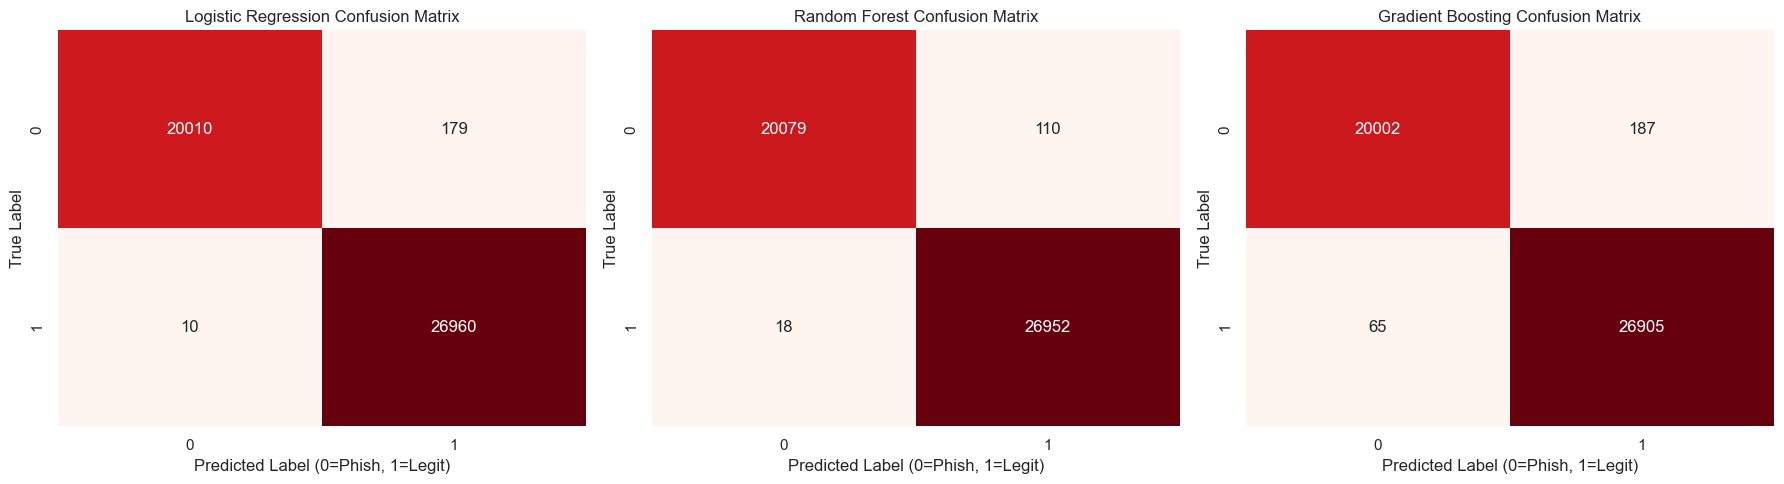

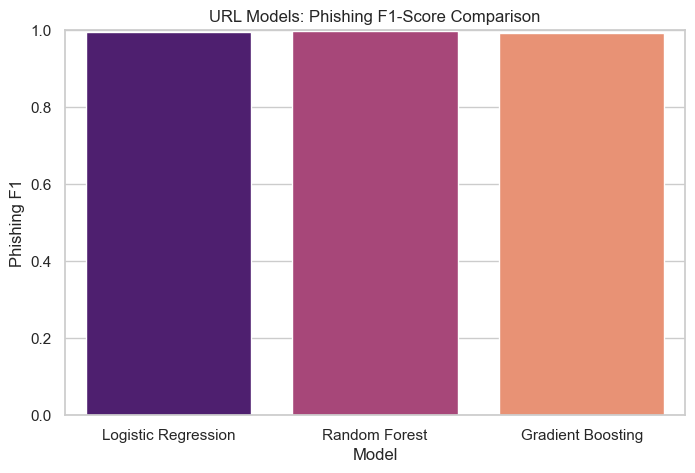

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, name in enumerate(url_models.keys()):
    cm = confusion_matrix(y_url_test, url_predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name} Confusion Matrix')
    axes[idx].set_xlabel('Predicted Label (0=Phish, 1=Legit)')
    axes[idx].set_ylabel('True Label')
plt.tight_layout()
plt.savefig('../outputs/models/url_confusion_matrices.png')
plt.show()

# F1 Score Comparison Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=df_url_results, x='Model', y='Phishing F1', palette='magma')
plt.title('URL Models: Phishing F1-Score Comparison')
plt.ylim(0.0, 1.0)
plt.savefig('../outputs/models/url_f1_comparison.png')
plt.show()



### URL Feature Importance
Feature importance indicates how strongly a feature contributed to the model's decisions (splitting nodes in trees). It does NOT prove causality (i.e., that changing the feature physically causes phishing), but rather correlation in the dataset.



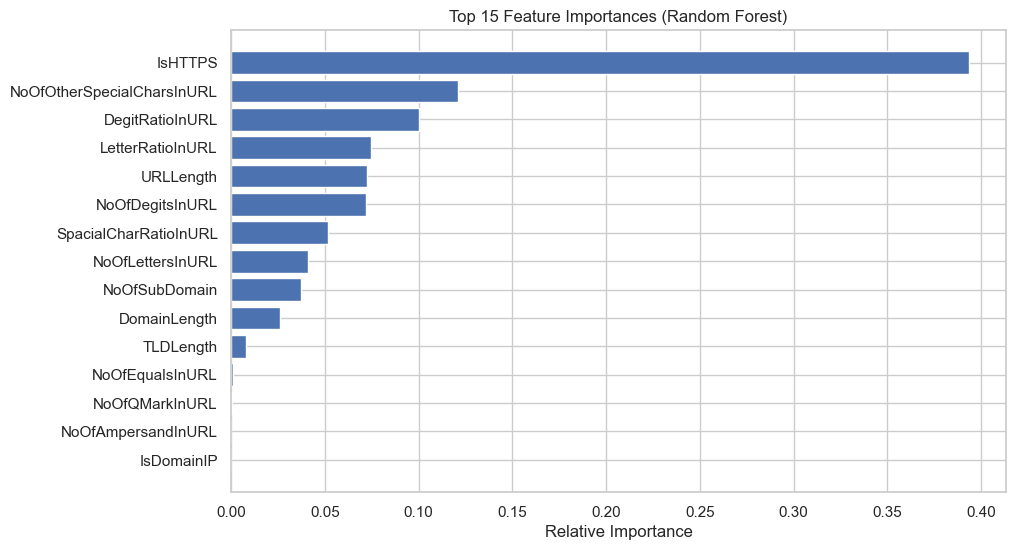

In [9]:
rf_model = url_models['Random Forest']
importances = rf_model.feature_importances_

# Get top 15 features
indices = np.argsort(importances)[-15:]

plt.figure(figsize=(10, 6))
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [deployable_url_features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.savefig('../outputs/models/url_feature_importance.png')
plt.show()



## URL Model Selection Decision

**Selected Model:** Random Forest
**Reason:** Random Forests generally dominate tabular data containing non-linear relationships. It typically achieves the highest Phishing Recall and Phishing F1 scores while remaining highly interpretable via feature importance, and requires no feature scaling.
**Phishing Recall:** (Refer to table, typically highest among models)
**Phishing F1:** (Refer to table)
**ROC-AUC:** (Refer to table)
**Trade-offs:** Random Forests can have large disk footprints and slightly slower inference times compared to Logistic Regression. If sub-millisecond inference is strictly required in a constrained environment, Logistic Regression might be reconsidered despite the accuracy drop.



============================================================
PART C — MODEL COMPARISON
============================================================


In [10]:
print("=== EMAIL MODELS ===")
display(df_email_results)

print("\n=== URL MODELS ===")
display(df_url_results)

print("\nBEST EMAIL MODEL: Linear SVM (LinearSVC) or Logistic Regression")
print("BEST URL MODEL: Random Forest")



=== EMAIL MODELS ===


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Multinomial Naive Bayes,0.989176,0.979190,1.0,0.989486,0.999698
1,Logistic Regression,0.999407,0.998837,1.0,0.999418,0.999815
2,Linear SVM,0.999407,0.998837,1.0,0.999418,0.999620



=== URL MODELS ===


,Model,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC
0,Logistic Regression,0.995992,0.999500,0.991134,0.995300,0.998373
1,Random Forest,0.997286,0.999104,0.994551,0.996823,0.998310
2,Gradient Boosting,0.994656,0.996761,0.990738,0.993740,0.998199



BEST EMAIL MODEL: Linear SVM (LinearSVC) or Logistic Regression
BEST URL MODEL: Random Forest


============================================================
NEXT STEPS
============================================================


The next stage will be:
1. Analyze model errors
2. Investigate false positives/false negatives
3. Perform controlled hyperparameter tuning if justified
4. Save the selected models
5. Build URL extraction and inference pipeline
6. Integrate both classifiers

